# House Price Prediction Project

This completed notebook follows the original assignment in `main.ipynb`: build machine
learning models to predict house sale prices, explain data cleaning and preprocessing,
train and validate several regression models, compare them with regression metrics, and
preserve every row from `test.csv` when producing final predictions.

The original raw files are left unchanged. All learned preprocessing is fitted only on
the labeled training data or the training split used inside validation, so the validation
set and the assignment test file do not leak information into model fitting.

## 1. Project Overview and Objectives

The project uses the Ames housing data fields described in `data_description.txt`.
The goal is to predict the sale price of a property from physical, location, quality,
sale, and amenity features.

The main objectives are:

1. Inspect the original assignment, data files, column descriptions, missing values,
   and target variable.
2. Build a leakage-safe preprocessing workflow for numeric and categorical variables.
3. Train a simple baseline and several regression algorithms.
4. Compare models on an untouched validation split using MAE, RMSE, and R2.
5. Fit the selected final model on all labeled rows in `train.csv` and produce one
   prediction for every row in `test.csv`, preserving the original order and IDs.

## 2. Imports and Configuration

The notebook uses established pandas, matplotlib, seaborn, and scikit-learn tools.
A fixed random seed is used for reproducibility.

In [1]:
from pathlib import Path
import json
import math
import textwrap
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 140)

RANDOM_STATE = 42
PROJECT_DIR = Path.cwd()
TRAIN_PATH = PROJECT_DIR / "train.csv"
TEST_PATH = PROJECT_DIR / "test.csv"
DESCRIPTION_PATH = PROJECT_DIR / "data_description.txt"
ORIGINAL_NOTEBOOK_PATH = PROJECT_DIR / "main.ipynb"
COMPARISON_PATH = PROJECT_DIR / "model_comparison.csv"
PREDICTION_PATH = PROJECT_DIR / "test_predictions.csv"
README_PATH = PROJECT_DIR / "README.md"

sns.set_theme(style="whitegrid", context="notebook")

## 3. Original Assignment and File Check

The original assignment template is intentionally preserved as `main.ipynb`. This
section reads it and confirms the required raw files are present.

In [2]:
required_files = [ORIGINAL_NOTEBOOK_PATH, TRAIN_PATH, TEST_PATH, DESCRIPTION_PATH]
file_check = pd.DataFrame(
    {
        "file": [path.name for path in required_files],
        "exists": [path.exists() for path in required_files],
        "size_bytes": [path.stat().st_size if path.exists() else np.nan for path in required_files],
    }
)
display(file_check)
assert file_check["exists"].all(), "One or more required project files are missing."

with ORIGINAL_NOTEBOOK_PATH.open("r", encoding="utf-8") as f:
    original_notebook = json.load(f)

assignment_text = []
for cell in original_notebook.get("cells", []):
    if cell.get("cell_type") == "markdown":
        assignment_text.append("".join(cell.get("source", [])))

print("\n\n".join(assignment_text))

,file,exists,size_bytes
0,main.ipynb,True,1529
1,train.csv,True,409385
2,test.csv,True,46280
3,data_description.txt,True,13370


### Project 1 - House Price

You are provided with a dataset containing information about houses and **prices**. The dataset is already split into `train.csv` and `test.csv`. The `data_description.txt` file contains descriptions of the columns.

**Goal:** Build models to predict house prices.

Please include detailed explanations of the following steps:

1. Data cleaning and preprocessing.

2. Model training and validation.

3. Model comparison based on regression metrics.

**Note:** You are **encouraged** to look for other machine learning algorithms online (beyond the course material), but you must study and understand these algorithms. You must not remove any rows from the `test.csv` file.


## 4. Data Loading and Initial Inspection

The target column is identified from the training data. In this dataset it is
`SalePrice`. The assignment test file also contains a `SalePrice` column, but because
`test.csv` is designated as the prediction file, that column is not used for training,
tuning, model selection, or preprocessing. It is removed from the test feature matrix
before predictions are generated.

In [3]:
train_raw = pd.read_csv(TRAIN_PATH)
test_raw = pd.read_csv(TEST_PATH)
data_description = DESCRIPTION_PATH.read_text(encoding="utf-8")

target_candidates = [c for c in train_raw.columns if c.lower() in {"saleprice", "sale_price", "price"}]
target_col = "SalePrice" if "SalePrice" in train_raw.columns else (target_candidates[0] if target_candidates else None)
assert target_col is not None, "No target column could be identified in train.csv."
assert target_col in train_raw.columns, "The target column is not present in train.csv."

test_contains_target = target_col in test_raw.columns
feature_columns_in_train = [c for c in train_raw.columns if c != target_col]
test_feature_columns = [c for c in test_raw.columns if c != target_col]

inspection_summary = pd.DataFrame(
    [
        {"item": "train.csv shape", "value": str(train_raw.shape)},
        {"item": "test.csv shape", "value": str(test_raw.shape)},
        {"item": "target column", "value": target_col},
        {"item": "target present in train.csv", "value": target_col in train_raw.columns},
        {"item": "target present in test.csv", "value": test_contains_target},
        {"item": "duplicate rows in train.csv", "value": int(train_raw.duplicated().sum())},
        {"item": "duplicate rows in test.csv", "value": int(test_raw.duplicated().sum())},
        {"item": "train features missing from test features", "value": sorted(set(feature_columns_in_train) - set(test_feature_columns))},
        {"item": "extra test feature columns", "value": sorted(set(test_feature_columns) - set(feature_columns_in_train))},
    ]
)
display(inspection_summary)

print("Training data sample:")
display(train_raw.head())
print("Test data sample:")
display(test_raw.head())

dtype_summary = (
    train_raw.dtypes.astype(str)
    .value_counts()
    .rename_axis("dtype")
    .reset_index(name="column_count")
)
display(dtype_summary)

,item,value
0,train.csv shape,"(1314, 81)"
1,test.csv shape,"(146, 81)"
2,target column,SalePrice
3,target present in train.csv,True
4,target present in test.csv,True
5,duplicate rows in train.csv,0
6,duplicate rows in test.csv,0
7,train features missing from test features,[]
8,extra test feature columns,[]


Training data sample:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1030,160,RM,21.0,1680,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,BrDale,Norm,Norm,Twnhs,2Story,6,7,1972,1972,Gable,CompShg,HdBoard,HdBoard,BrkFace,281.0,TA,TA,CBlock,TA,TA,No,BLQ,317,Unf,0,355,672,GasA,Gd,Y,SBrkr,672,546,0,1218,0,1,1,1,3,1,TA,7,Typ,0,NaN,Detchd,1972.0,Unf,1,264,TA,TA,Y,0,28,0,0,0,0,NaN,NaN,NaN,0,5,2006,WD,Normal,118000
1,366,70,RM,59.0,10690,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,IDOTRR,Norm,Norm,1Fam,2Story,5,7,1920,1997,Hip,CompShg,VinylSd,VinylSd,NaN,0.0,TA,Gd,CBlock,TA,Fa,No,Rec,456,Unf,0,216,672,GasA,Gd,Y,FuseA,672,672,0,1344,0,0,1,0,3,1,TA,6,Typ,0,NaN,Detchd,1964.0,Unf,1,468,TA,Fa,Y,0,128,218,0,0,0,NaN,NaN,NaN,0,7,2009,WD,Normal,147000
2,883,60,RL,NaN,9636,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Gilbert,Norm,Norm,1Fam,2Story,6,5,1992,1993,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,Unf,0,Unf,0,808,808,GasA,Gd,Y,SBrkr,808,785,0,1593,0,0,2,1,3,1,TA,7,Typ,1,TA,BuiltIn,1993.0,RFn,2,389,TA,TA,Y,342,40,0,0,0,0,NaN,MnPrv,NaN,0,12,2009,WD,Normal,178000
3,94,190,C (all),60.0,7200,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,OldTown,Norm,Norm,2fmCon,2.5Unf,6,6,1910,1998,Hip,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,BrkTil,TA,Fa,Mn,Rec,1046,Unf,0,168,1214,GasW,Ex,N,SBrkr,1260,1031,0,2291,0,1,2,0,4,2,TA,9,Typ,1,Gd,Detchd,1900.0,Unf,2,506,TA,TA,Y,0,0,0,0,99,0,NaN,NaN,NaN,0,11,2007,WD,Normal,133900
4,1360,20,RL,129.0,16737,Pave,NaN,Reg,Lvl,AllPub,FR3,Gtl,NridgHt,Norm,Norm,1Fam,1Story,9,5,2004,2005,Hip,CompShg,VinylSd,VinylSd,BrkFace,66.0,Gd,TA,PConc,Ex,TA,Av,GLQ,1447,Unf,0,533,1980,GasA,Ex,Y,SBrkr,1980,0,0,1980,1,0,2,0,3,1,Ex,8,Typ,1,Gd,Attchd,2004.0,Fin,3,770,TA,TA,Y,194,45,0,0,0,0,NaN,NaN,NaN,0,9,2006,WD,Normal,315000


Test data sample:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1227,60,RL,86.0,14598,Pave,NaN,IR1,Lvl,AllPub,CulDSac,Gtl,Somerst,Feedr,Norm,1Fam,2Story,6,5,2007,2007,Gable,CompShg,VinylSd,VinylSd,Stone,74.0,Gd,TA,PConc,Gd,TA,Mn,Unf,0,Unf,0,894,894,GasA,Ex,Y,SBrkr,894,1039,0,1933,0,0,2,1,4,1,Gd,9,Typ,1,Gd,BuiltIn,2007.0,Fin,3,668,TA,TA,Y,100,18,0,0,0,0,NaN,NaN,NaN,0,1,2008,WD,Normal,214000
1,932,20,RL,70.0,9100,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,5,6,1965,1965,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,BLQ,338,Rec,466,121,925,GasA,Ex,Y,SBrkr,925,0,0,925,0,1,1,0,2,1,TA,5,Typ,0,NaN,Detchd,1965.0,Unf,1,429,TA,TA,Y,0,0,0,0,0,0,NaN,GdWo,NaN,0,7,2009,WD,Normal,117500
2,647,20,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,5,5,1950,1950,Hip,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,NaN,NaN,NaN,NaN,0,NaN,0,0,0,GasA,Gd,Y,SBrkr,1048,0,0,1048,0,0,1,0,3,1,TA,7,Min1,0,NaN,Detchd,1950.0,Unf,2,420,TA,TA,Y,0,27,0,0,0,0,NaN,NaN,NaN,0,7,2008,WD,Normal,98300
3,547,50,RL,70.0,8737,Pave,NaN,IR1,Bnk,AllPub,Inside,Gtl,BrkSide,Norm,Norm,1Fam,1.5Fin,6,7,1923,1950,Gable,CompShg,BrkFace,Wd Sdng,NaN,0.0,TA,TA,BrkTil,Gd,TA,No,Rec,300,Unf,0,765,1065,GasA,Ex,Y,FuseA,915,720,0,1635,0,0,1,1,3,1,TA,6,Typ,1,Gd,Detchd,1950.0,Unf,2,440,TA,TA,Y,0,38,0,144,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,210000
4,812,120,RM,NaN,4438,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,TwnhsE,1Story,6,5,2004,2004,Gable,CompShg,VinylSd,VinylSd,BrkFace,169.0,Gd,TA,PConc,Gd,TA,Gd,GLQ,662,Unf,0,186,848,GasA,Ex,Y,SBrkr,848,0,0,848,1,0,1,0,1,1,Gd,4,Typ,1,Gd,Attchd,2004.0,Fin,2,420,TA,TA,Y,140,0,0,0,0,0,NaN,NaN,NaN,0,6,2008,ConLD,Normal,144500


,dtype,column_count
0,str,43
1,int64,35
2,float64,3


## 5. Exploratory Data Analysis

This section checks missing values, the target distribution, important numerical
relationships, and unusual values. No rows are removed during EDA. Potential outliers
are inspected and retained unless there is a defensible reason to exclude them.

Top missing values in train.csv:


,missing_count,missing_percent,dtype
PoolQC,1307,99.467275,str
MiscFeature,1266,96.347032,str
Alley,1231,93.683409,str
Fence,1068,81.278539,str
MasVnrType,788,59.969559,str
FireplaceQu,621,47.260274,str
LotFrontage,236,17.960426,float64
GarageType,78,5.936073,str
GarageYrBlt,78,5.936073,float64
GarageFinish,78,5.936073,str


Top missing values in test.csv:


,missing_count,missing_percent,dtype
PoolQC,146,100.000000,float64
MiscFeature,140,95.890411,str
Alley,138,94.520548,str
Fence,111,76.027397,str
MasVnrType,84,57.534247,str
FireplaceQu,69,47.260274,str
LotFrontage,23,15.753425,float64
BsmtFinType1,6,4.109589,str
BsmtCond,6,4.109589,str
BsmtQual,6,4.109589,str


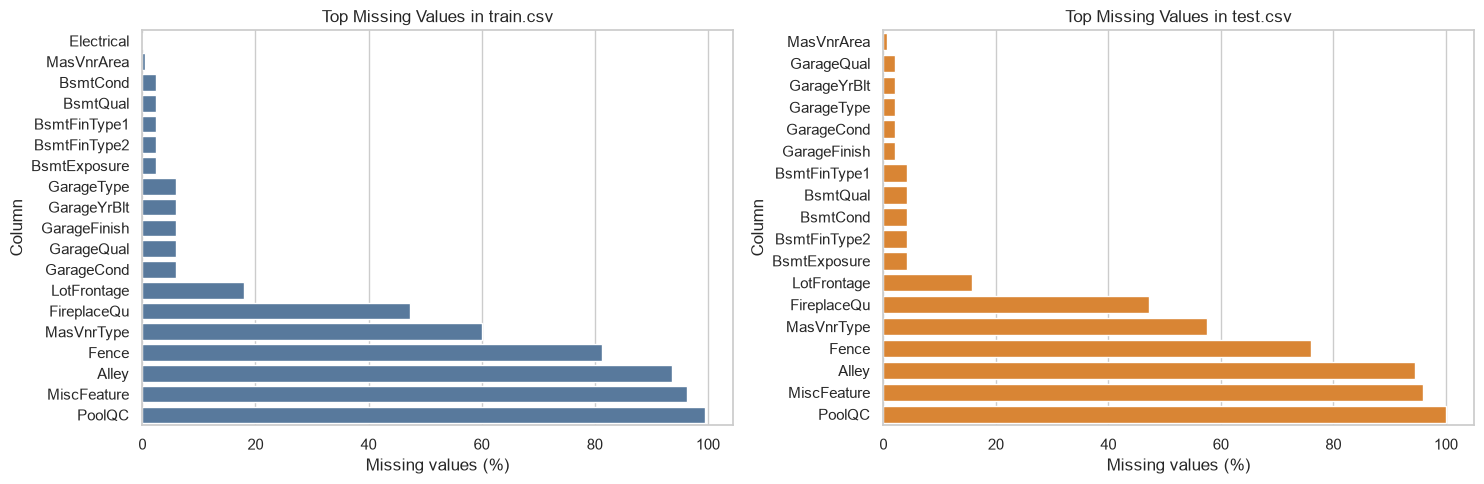

In [4]:
def missing_summary(df: pd.DataFrame) -> pd.DataFrame:
    missing_count = df.isna().sum()
    summary = pd.DataFrame(
        {
            "missing_count": missing_count,
            "missing_percent": missing_count / len(df) * 100,
            "dtype": df.dtypes.astype(str),
        }
    )
    return summary[summary["missing_count"] > 0].sort_values("missing_count", ascending=False)

train_missing = missing_summary(train_raw)
test_missing = missing_summary(test_raw)

print("Top missing values in train.csv:")
display(train_missing.head(25))
print("Top missing values in test.csv:")
display(test_missing.head(25))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top_train_missing = train_missing.head(20).sort_values("missing_percent")
sns.barplot(data=top_train_missing, x="missing_percent", y=top_train_missing.index, ax=axes[0], color="#4C78A8")
axes[0].set_title("Top Missing Values in train.csv")
axes[0].set_xlabel("Missing values (%)")
axes[0].set_ylabel("Column")

top_test_missing = test_missing.head(20).sort_values("missing_percent")
sns.barplot(data=top_test_missing, x="missing_percent", y=top_test_missing.index, ax=axes[1], color="#F58518")
axes[1].set_title("Top Missing Values in test.csv")
axes[1].set_xlabel("Missing values (%)")
axes[1].set_ylabel("Column")
plt.tight_layout()
plt.show()

,SalePrice
count,1314.000000
mean,181045.474886
std,79863.285965
min,34900.000000
25%,130000.000000
50%,162950.000000
75%,214000.000000
max,755000.000000


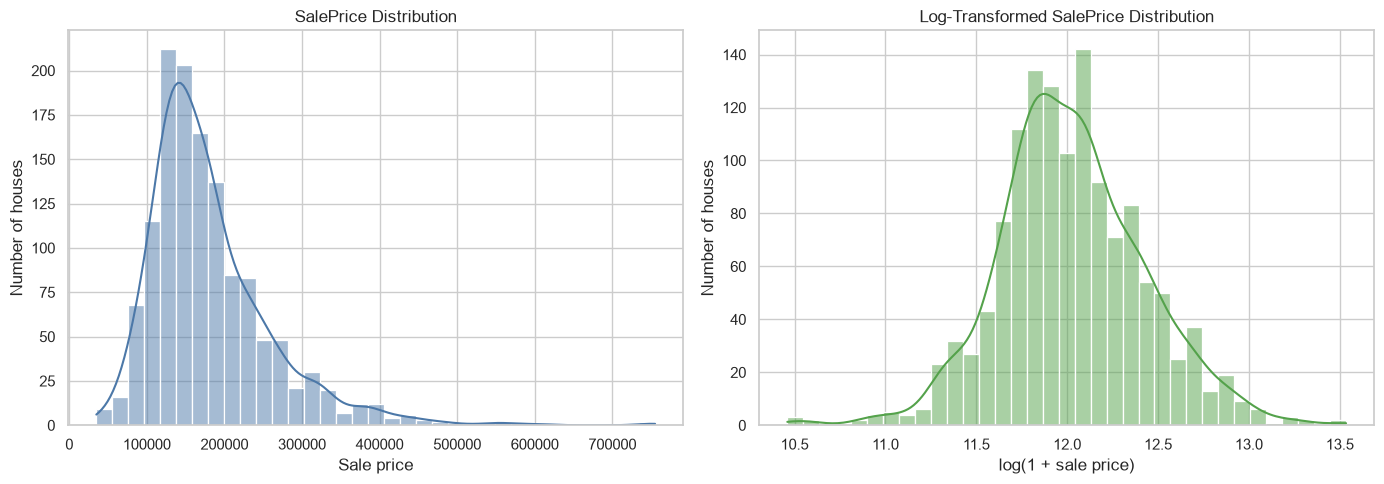

SalePrice skewness: 1.876
log(1 + SalePrice) skewness: 0.113


In [5]:
target_description = train_raw[target_col].describe().to_frame("SalePrice")
display(target_description)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(train_raw[target_col], kde=True, bins=35, ax=axes[0], color="#4C78A8")
axes[0].set_title("SalePrice Distribution")
axes[0].set_xlabel("Sale price")
axes[0].set_ylabel("Number of houses")

sns.histplot(np.log1p(train_raw[target_col]), kde=True, bins=35, ax=axes[1], color="#54A24B")
axes[1].set_title("Log-Transformed SalePrice Distribution")
axes[1].set_xlabel("log(1 + sale price)")
axes[1].set_ylabel("Number of houses")
plt.tight_layout()
plt.show()

print(f"SalePrice skewness: {train_raw[target_col].skew():.3f}")
print(f"log(1 + SalePrice) skewness: {np.log1p(train_raw[target_col]).skew():.3f}")

,correlation_with_saleprice
OverallQual,0.792541
GrLivArea,0.697301
GarageCars,0.642377
GarageArea,0.633452
TotalBsmtSF,0.614149
1stFlrSF,0.604703
FullBath,0.555294
YearBuilt,0.529912
TotRmsAbvGrd,0.529226
YearRemodAdd,0.510579


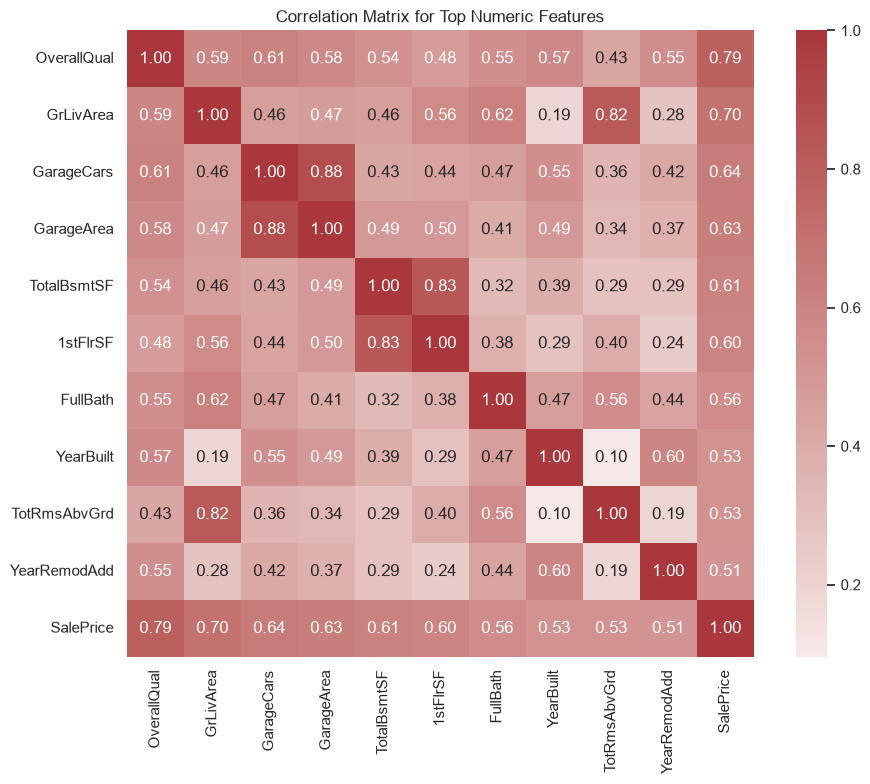

In [6]:
numeric_train = train_raw.select_dtypes(include=[np.number])
numeric_for_corr = numeric_train.drop(columns=["Id"], errors="ignore")
corr_with_target = (
    numeric_for_corr.corr(numeric_only=True)[target_col]
    .drop(target_col)
    .sort_values(key=lambda s: s.abs(), ascending=False)
)
top_corr = corr_with_target.head(12)
display(top_corr.to_frame("correlation_with_saleprice"))

heatmap_columns = list(top_corr.index[:10]) + [target_col]
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_for_corr[heatmap_columns].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Correlation Matrix for Top Numeric Features")
plt.tight_layout()
plt.show()

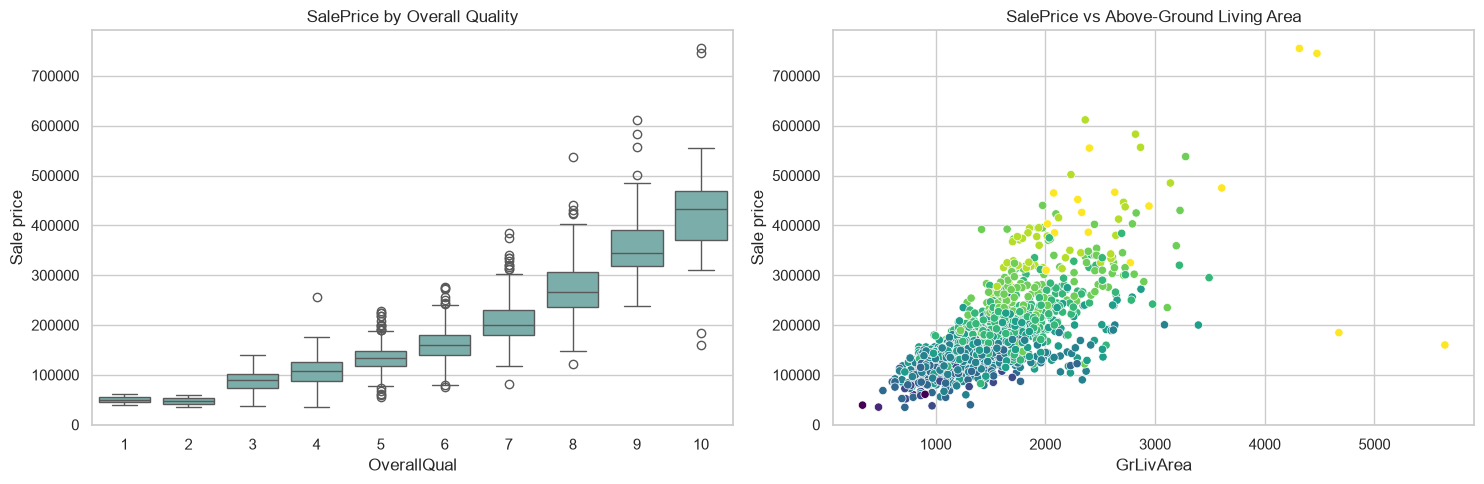

,Id,GrLivArea,SalePrice,OverallQual,Neighborhood
649,1299,5642,160000,10,Edwards
672,524,4676,184750,10,Edwards
877,1183,4476,745000,10,NoRidge
585,692,4316,755000,10,NoRidge
424,186,3608,475000,10,OldTown
283,305,3493,295000,7,OldTown
885,636,3395,200000,6,SWISU
590,770,3279,538000,8,StoneBr


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=train_raw, x="OverallQual", y=target_col, ax=axes[0], color="#72B7B2")
axes[0].set_title("SalePrice by Overall Quality")
axes[0].set_xlabel("OverallQual")
axes[0].set_ylabel("Sale price")

sns.scatterplot(data=train_raw, x="GrLivArea", y=target_col, hue="OverallQual", palette="viridis", ax=axes[1], legend=False)
axes[1].set_title("SalePrice vs Above-Ground Living Area")
axes[1].set_xlabel("GrLivArea")
axes[1].set_ylabel("Sale price")
plt.tight_layout()
plt.show()

outlier_review = train_raw.nlargest(8, "GrLivArea")[["Id", "GrLivArea", target_col, "OverallQual", "Neighborhood"]]
display(outlier_review)

### EDA Interpretation

The target is right-skewed, which is typical for sale prices because a small number of
expensive homes can be much higher than the median. A log transformation reduces this
skewness and is useful for stabilizing model training. `OverallQual`, `GrLivArea`,
garage capacity, basement area, and first-floor square footage are among the strongest
numerical relationships with price. Several columns have many missing values, but the
data dictionary explains that many of these missing values represent absent property
features, not data-entry errors. High-area observations are retained because they are
valid houses and the assignment asks to preserve useful information rather than delete
observations just because they are unusual.

## 6. Data Cleaning and Preprocessing

Preprocessing choices are based on the data dictionary:

- `Id` is a unique row identifier. It is preserved in output files but excluded from
  predictive features because it has no real market meaning.
- `MSSubClass` is stored as an integer but represents dwelling categories, so it is
  treated as categorical.
- Missing categorical values documented as absent property features are imputed with
  the category `"None"`.
- Other missing categorical values are imputed with the most frequent training value.
- `GarageYrBlt` and `MasVnrArea` are imputed with 0 when missing, because missingness
  is commonly tied to no garage or no masonry veneer; missing indicators are also added.
- Remaining numeric columns use median imputation with missing indicators.
- Categorical columns are encoded with `OneHotEncoder(handle_unknown="ignore")` so
  unseen validation or test categories do not break the model.
- Numeric features are scaled with `StandardScaler`, which is useful for Ridge
  regression and harmless for tree models after monotonic numeric scaling.

The preprocessing is placed inside scikit-learn pipelines so imputers, encoders, and
scalers are fitted only on the relevant training data.

In [8]:
documented_absence_categories = [
    "Alley",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "PoolQC",
    "Fence",
    "MiscFeature",
    "MasVnrType",
]

zero_impute_numeric_candidates = ["GarageYrBlt", "MasVnrArea"]
categorical_code_columns = ["MSSubClass"]
identifier_columns = [col for col in ["Id"] if col in train_raw.columns]

def prepare_feature_frame(df: pd.DataFrame) -> pd.DataFrame:
    prepared = df.copy()
    for col in categorical_code_columns:
        if col in prepared.columns:
            prepared[col] = prepared[col].astype("string")
    return prepared

X_full_raw = train_raw.drop(columns=[target_col])
y_full = train_raw[target_col].copy()

test_features_raw = test_raw.drop(columns=[target_col], errors="ignore")
test_features_raw = test_features_raw.reindex(columns=X_full_raw.columns)

X_full_prepared = prepare_feature_frame(X_full_raw)
test_features_prepared = prepare_feature_frame(test_features_raw)

model_feature_columns = [c for c in X_full_prepared.columns if c not in identifier_columns]
X_full = X_full_prepared[model_feature_columns].copy()
X_test_for_prediction = test_features_prepared[model_feature_columns].copy()

numeric_cols = [col for col in X_full.columns if pd.api.types.is_numeric_dtype(X_full[col])]
categorical_cols = [col for col in X_full.columns if col not in numeric_cols]

none_category_cols = [col for col in documented_absence_categories if col in categorical_cols]
other_category_cols = [col for col in categorical_cols if col not in none_category_cols]
zero_impute_numeric_cols = [col for col in zero_impute_numeric_candidates if col in numeric_cols]
median_numeric_cols = [col for col in numeric_cols if col not in zero_impute_numeric_cols]

preprocessing_summary = pd.DataFrame(
    [
        {"group": "identifier columns excluded from model", "columns": identifier_columns, "count": len(identifier_columns)},
        {"group": "median-imputed numeric columns", "columns": median_numeric_cols, "count": len(median_numeric_cols)},
        {"group": "zero-imputed numeric columns", "columns": zero_impute_numeric_cols, "count": len(zero_impute_numeric_cols)},
        {"group": "absence-imputed categorical columns", "columns": none_category_cols, "count": len(none_category_cols)},
        {"group": "mode-imputed categorical columns", "columns": other_category_cols, "count": len(other_category_cols)},
    ]
)
display(preprocessing_summary)

def build_preprocessor() -> ColumnTransformer:
    transformers = []
    if median_numeric_cols:
        transformers.append(
            (
                "numeric_median",
                Pipeline(
                    steps=[
                        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                        ("scaler", StandardScaler()),
                    ]
                ),
                median_numeric_cols,
            )
        )
    if zero_impute_numeric_cols:
        transformers.append(
            (
                "numeric_zero",
                Pipeline(
                    steps=[
                        ("imputer", SimpleImputer(strategy="constant", fill_value=0, add_indicator=True)),
                        ("scaler", StandardScaler()),
                    ]
                ),
                zero_impute_numeric_cols,
            )
        )
    if none_category_cols:
        transformers.append(
            (
                "categorical_absence",
                Pipeline(
                    steps=[
                        ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
                        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
                    ]
                ),
                none_category_cols,
            )
        )
    if other_category_cols:
        transformers.append(
            (
                "categorical_mode",
                Pipeline(
                    steps=[
                        ("imputer", SimpleImputer(strategy="most_frequent")),
                        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
                    ]
                ),
                other_category_cols,
            )
        )
    return ColumnTransformer(transformers=transformers, remainder="drop", verbose_feature_names_out=False)

,group,columns,count
0,identifier columns excluded from model,[Id],1
1,median-imputed numeric columns,"[LotFrontage, LotArea, OverallQual, OverallCon...",33
2,zero-imputed numeric columns,"[GarageYrBlt, MasVnrArea]",2
3,absence-imputed categorical columns,"[Alley, BsmtQual, BsmtCond, BsmtExposure, Bsmt...",15
4,mode-imputed categorical columns,"[MSSubClass, MSZoning, Street, LotShape, LandC...",29


## 7. Train/Validation Split

The labeled training data is split into an 80 percent training subset and a 20 percent
validation subset. The validation subset remains untouched during fitting and is used
only for final model comparison.

In [9]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X_full,
    y_full,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame(
    [
        {"subset": "training split", "rows": len(X_train), "target_mean": y_train.mean(), "target_median": y_train.median()},
        {"subset": "validation split", "rows": len(X_valid), "target_mean": y_valid.mean(), "target_median": y_valid.median()},
    ]
)
display(split_summary)

,subset,rows,target_mean,target_median
0,training split,1051,180620.556613,162000.0
1,validation split,263,182743.532319,165000.0


## 8. Regression Algorithms and Their Principles

The following algorithms are evaluated:

**Dummy Regressor.** This baseline predicts a constant value, here the median training
price. It is simple, transparent, and useful for checking whether real models improve
over a naive rule. Its weakness is that it ignores all house features.

**Ridge Regression.** Ridge is a regularized linear regression model. It estimates a
weighted linear relationship between features and target while penalizing large
coefficients through the `alpha` hyperparameter. It is fast and interpretable, but it
can underfit nonlinear relationships unless feature engineering captures them.

**Decision Tree Regressor.** A decision tree recursively splits the feature space into
regions with similar prices. It can model nonlinear effects and interactions, but a
deep tree can overfit. The implementation limits complexity with `max_depth` and
`min_samples_leaf`.

**Random Forest Regressor.** A random forest averages many decision trees trained on
bootstrapped samples and random feature subsets. It usually improves stability and
reduces overfitting compared with a single tree. Important hyperparameters include
`n_estimators`, `max_features`, and `min_samples_leaf`.

**Extra Trees Regressor.** Extra Trees is another tree ensemble. It uses additional
randomness when choosing split thresholds, which can reduce variance and train quickly.
It may be less precise than a carefully tuned forest on some datasets, but it is a
strong tabular-data benchmark.

**Gradient Boosting Regressor.** Gradient boosting builds trees sequentially, where
each new tree attempts to correct the errors of the current ensemble. It can produce
strong predictions on structured data, but it is more sensitive to hyperparameters such
as `learning_rate`, `n_estimators`, and `max_depth`.

All models are trained on `log(1 + SalePrice)` through `TransformedTargetRegressor`
and transformed back to the original price scale before calculating metrics.

## 9. Model Training

A helper function constructs a fresh preprocessing pipeline for each model. This avoids
shared fitted state between models and keeps the validation comparison fair.

In [10]:
def build_model(model):
    regression_pipeline = Pipeline(
        steps=[
            ("preprocessor", build_preprocessor()),
            ("model", model),
        ]
    )
    return TransformedTargetRegressor(
        regressor=regression_pipeline,
        func=np.log1p,
        inverse_func=np.expm1,
        check_inverse=False,
    )

model_specs = {
    "Dummy Regressor": DummyRegressor(strategy="median"),
    "Ridge Regression": Ridge(alpha=20.0),
    "Decision Tree Regressor": DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=RANDOM_STATE),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=300,
        max_features=0.70,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "Extra Trees Regressor": ExtraTreesRegressor(
        n_estimators=300,
        max_features=0.70,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "Gradient Boosting Regressor": GradientBoostingRegressor(
        n_estimators=350,
        learning_rate=0.035,
        max_depth=3,
        subsample=0.90,
        random_state=RANDOM_STATE,
    ),
}

fitted_models = {}
validation_predictions = {}
training_notes = []

for model_name, model in model_specs.items():
    start_time = time.perf_counter()
    estimator = build_model(model)
    estimator.fit(X_train, y_train)
    raw_predictions = estimator.predict(X_valid)
    predictions = np.maximum(raw_predictions, 0)
    elapsed = time.perf_counter() - start_time

    fitted_models[model_name] = estimator
    validation_predictions[model_name] = predictions
    training_notes.append({"Model": model_name, "Training seconds": elapsed})

display(pd.DataFrame(training_notes))

,Model,Training seconds
0,Dummy Regressor,0.199399
1,Ridge Regression,0.169156
2,Decision Tree Regressor,0.214910
3,Random Forest Regressor,2.866974
4,Extra Trees Regressor,2.835086
5,Gradient Boosting Regressor,7.679164


## 10. Validation and Regression Metrics

Metrics are calculated on the original house-price scale:

- **MAE (Mean Absolute Error)** is the average absolute difference between predicted
  and actual prices. Lower is better.
- **RMSE (Root Mean Squared Error)** is the square root of the mean squared error. It
  penalizes large errors more strongly than MAE. Lower is better.
- **R2 (Coefficient of Determination)** measures the proportion of target variance
  explained by the model on the validation set. Higher is generally better, with 1.0
  representing perfect predictions.

In [11]:
def calculate_regression_metrics(y_true, y_pred) -> dict:
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

metric_rows = []
for model_name, predictions in validation_predictions.items():
    metrics = calculate_regression_metrics(y_valid, predictions)
    metric_rows.append({"Model": model_name, **metrics})

model_comparison = (
    pd.DataFrame(metric_rows)
    .merge(pd.DataFrame(training_notes), on="Model", how="left")
    .sort_values(["RMSE", "MAE"], ascending=[True, True])
    .reset_index(drop=True)
)
model_comparison.insert(0, "Rank_by_RMSE", np.arange(1, len(model_comparison) + 1))
model_comparison.to_csv(COMPARISON_PATH, index=False)

display(
    model_comparison.round(
        {
            "MAE": 2,
            "RMSE": 2,
            "R2": 4,
            "Training seconds": 2,
        }
    )
)

,Rank_by_RMSE,Model,MAE,RMSE,R2,Training seconds
0,1,Extra Trees Regressor,20128.11,43994.54,0.7399,2.84
1,2,Gradient Boosting Regressor,18014.51,45115.97,0.7265,7.68
2,3,Random Forest Regressor,19130.08,45691.13,0.7194,2.87
3,4,Decision Tree Regressor,27700.46,52412.85,0.6308,0.21
4,5,Dummy Regressor,56854.58,88721.22,-0.0578,0.20
5,6,Ridge Regression,25704.53,171037.68,-2.9314,0.17


## 11. Model Comparison

The selected model is the one with the lowest validation RMSE, using MAE as a secondary
check and R2 as supporting context. RMSE is prioritized because large pricing mistakes
are especially important in a house-price prediction task.

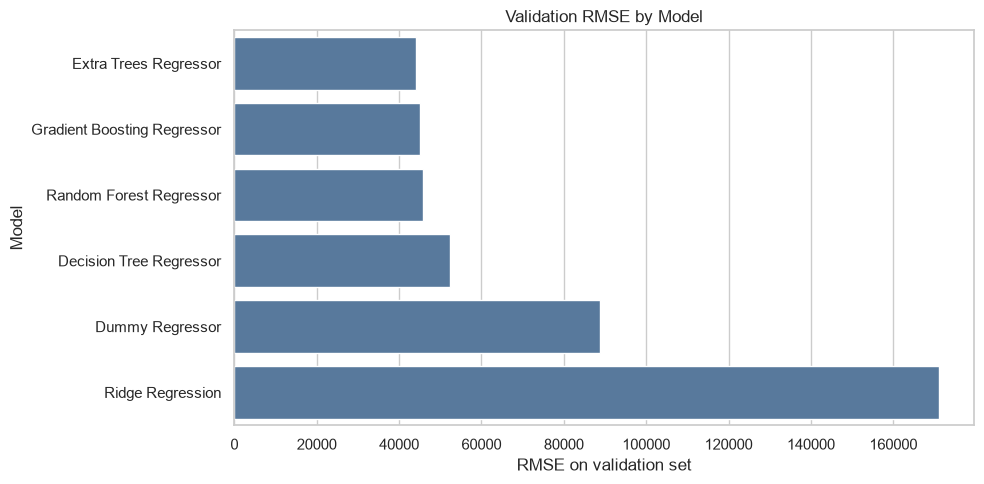

Best model by validation RMSE: Extra Trees Regressor
{'MAE': 20128.111974646043, 'RMSE': 43994.54339136278, 'R2': 0.7398900686308221}


In [12]:
plt.figure(figsize=(10, 5))
plot_data = model_comparison.sort_values("RMSE", ascending=True)
sns.barplot(data=plot_data, x="RMSE", y="Model", color="#4C78A8")
plt.title("Validation RMSE by Model")
plt.xlabel("RMSE on validation set")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

best_model_name = model_comparison.loc[0, "Model"]
best_validation_metrics = model_comparison.loc[0, ["MAE", "RMSE", "R2"]].to_dict()
print(f"Best model by validation RMSE: {best_model_name}")
print(best_validation_metrics)

## 12. Final Model Selection

The best validation model is refitted on all labeled rows from `train.csv` before
predicting the assignment test rows. The assignment test file is not used to choose the
model or fit preprocessing.

In [13]:
selection_markdown = f'''
**Selected model:** {best_model_name}

This model achieved the lowest validation RMSE among the evaluated candidates:

- MAE: {best_validation_metrics["MAE"]:,.2f}
- RMSE: {best_validation_metrics["RMSE"]:,.2f}
- R2: {best_validation_metrics["R2"]:.4f}

The model is selected from validation performance, not from model complexity or from
any information in `test.csv`. Its limitations are that predictions are based on the
available structured features, and unusual properties or market changes outside this
dataset may still be difficult to predict accurately.
'''
display(Markdown(selection_markdown))


**Selected model:** Extra Trees Regressor

This model achieved the lowest validation RMSE among the evaluated candidates:

- MAE: 20,128.11
- RMSE: 43,994.54
- R2: 0.7399

The model is selected from validation performance, not from model complexity or from
any information in `test.csv`. Its limitations are that predictions are based on the
available structured features, and unusual properties or market changes outside this
dataset may still be difficult to predict accurately.


## 13. Predictions on the Test Dataset

The final pipeline is trained on all labeled rows in `train.csv`. It then predicts a
price for every row in `test.csv`. If a model were to produce impossible negative
prices, predictions would be clipped at zero. With the log-target workflow, this is not
expected, but the safety check is retained.

In [14]:
final_model = build_model(model_specs[best_model_name])
final_model.fit(X_full, y_full)

final_test_predictions = final_model.predict(X_test_for_prediction)
final_test_predictions = np.maximum(final_test_predictions, 0)

if "Id" in test_raw.columns:
    prediction_output = pd.DataFrame(
        {
            "Id": test_raw["Id"].values,
            "PredictedSalePrice": final_test_predictions,
        }
    )
else:
    prediction_output = pd.DataFrame(
        {
            "OriginalRowNumber": np.arange(len(test_raw)),
            "PredictedSalePrice": final_test_predictions,
        }
    )

prediction_output.to_csv(PREDICTION_PATH, index=False)
display(prediction_output.head())

,Id,PredictedSalePrice
0,1227,228867.898829
1,932,124630.434032
2,647,117899.508724
3,547,168250.760465
4,812,147956.392121


## 14. Verification and Export of Results

The following checks verify that the prediction file preserves all `test.csv` rows,
preserves ID order when IDs exist, contains finite numeric predictions, and that the
comparison table was saved.

In [15]:
saved_predictions = pd.read_csv(PREDICTION_PATH)
saved_comparison = pd.read_csv(COMPARISON_PATH)

assert len(saved_predictions) == len(test_raw), "Prediction row count does not match test.csv."
assert saved_predictions["PredictedSalePrice"].notna().all(), "Predictions contain missing values."
assert np.isfinite(saved_predictions["PredictedSalePrice"]).all(), "Predictions contain non-finite values."
assert (saved_predictions["PredictedSalePrice"] >= 0).all(), "Predictions contain negative prices."
assert len(saved_predictions) == saved_predictions.shape[0], "Prediction file row count is inconsistent."

if "Id" in test_raw.columns:
    assert saved_predictions["Id"].equals(test_raw["Id"]), "Prediction IDs do not match original test order."

expected_models = set(model_specs.keys())
assert set(saved_comparison["Model"]) == expected_models, "Not all models are present in model_comparison.csv."
assert saved_comparison.iloc[0]["Model"] == best_model_name, "Saved comparison does not match selected model."

verification_summary = pd.DataFrame(
    [
        {"check": "Prediction rows equal len(test.csv)", "result": len(saved_predictions) == len(test_raw), "value": len(saved_predictions)},
        {"check": "Original test row count", "result": True, "value": len(test_raw)},
        {"check": "Prediction IDs preserve original order", "result": bool(saved_predictions["Id"].equals(test_raw["Id"])) if "Id" in test_raw.columns else "No Id column", "value": "checked"},
        {"check": "All predictions finite", "result": bool(np.isfinite(saved_predictions["PredictedSalePrice"]).all()), "value": "checked"},
        {"check": "All predictions non-negative", "result": bool((saved_predictions["PredictedSalePrice"] >= 0).all()), "value": "checked"},
        {"check": "Model comparison file rows", "result": len(saved_comparison) == len(model_specs), "value": len(saved_comparison)},
    ]
)
display(verification_summary)

,check,result,value
0,Prediction rows equal len(test.csv),True,146
1,Original test row count,True,146
2,Prediction IDs preserve original order,True,checked
3,All predictions finite,True,checked
4,All predictions non-negative,True,checked
5,Model comparison file rows,True,6


## 15. Conclusions

The following conclusion is generated from the actual validation results produced
during this run.

In [16]:
conclusion = f'''
The completed workflow inspected the original assignment and data dictionary, loaded
{len(train_raw):,} labeled training rows and {len(test_raw):,} assignment test rows,
excluded `Id` from modeling, handled documented absence values explicitly, and compared
{len(model_specs)} regression approaches on the same validation split.

The best model by validation RMSE was **{best_model_name}**, with MAE
**{best_validation_metrics["MAE"]:,.2f}**, RMSE **{best_validation_metrics["RMSE"]:,.2f}**,
and R2 **{best_validation_metrics["R2"]:.4f}**. It was selected because it had the
strongest validation error profile, not because it was the most complex model.

The final model was retrained on all rows from `train.csv` and produced
{len(saved_predictions):,} predictions for `test.csv`. The output preserves the original
test row order and IDs, and every predicted price is finite and non-negative.

Remaining limitations include the modest dataset size, possible sensitivity to rare
property categories, and the fact that validation performance estimates generalization
from a single random split rather than from a future housing market.
'''
display(Markdown(conclusion))


The completed workflow inspected the original assignment and data dictionary, loaded
1,314 labeled training rows and 146 assignment test rows,
excluded `Id` from modeling, handled documented absence values explicitly, and compared
6 regression approaches on the same validation split.

The best model by validation RMSE was **Extra Trees Regressor**, with MAE
**20,128.11**, RMSE **43,994.54**,
and R2 **0.7399**. It was selected because it had the
strongest validation error profile, not because it was the most complex model.

The final model was retrained on all rows from `train.csv` and produced
146 predictions for `test.csv`. The output preserves the original
test row order and IDs, and every predicted price is finite and non-negative.

Remaining limitations include the modest dataset size, possible sensitivity to rare
property categories, and the fact that validation performance estimates generalization
from a single random split rather than from a future housing market.


## 16. References

The following references were consulted for the algorithms and scikit-learn workflow:

- scikit-learn documentation: `Pipeline`, `ColumnTransformer`, `SimpleImputer`, and `OneHotEncoder`.
  https://scikit-learn.org/stable/
- scikit-learn documentation: `DummyRegressor`.
  https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html
- scikit-learn documentation: Ridge regression.
  https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression
- scikit-learn documentation: Decision trees for regression.
  https://scikit-learn.org/stable/modules/tree.html#regression
- scikit-learn documentation: Random forests, Extra Trees, and gradient tree boosting.
  https://scikit-learn.org/stable/modules/ensemble.html
- scikit-learn documentation: regression metrics.
  https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics

In [17]:
readme_text = f'''# House Price Prediction Project

This project predicts house sale prices from the provided `train.csv` and `test.csv`
files. The completed notebook is `main_completed.ipynb`.

## How to run

1. Open `main_completed.ipynb` in Jupyter.
2. Use a Python environment with pandas, numpy, scikit-learn, matplotlib, seaborn,
   nbformat, nbclient, and ipykernel installed.
3. Run all notebook cells from top to bottom.

The notebook uses relative paths, so run it from the project folder.

## Modeling summary

The evaluated models were:

- Dummy Regressor
- Ridge Regression
- Decision Tree Regressor
- Random Forest Regressor
- Extra Trees Regressor
- Gradient Boosting Regressor

The selected model was **{best_model_name}** because it had the lowest validation RMSE.

Validation metrics for the selected model:

- MAE: {best_validation_metrics["MAE"]:,.2f}
- RMSE: {best_validation_metrics["RMSE"]:,.2f}
- R2: {best_validation_metrics["R2"]:.4f}

## Output files

- `main_completed.ipynb`: completed and executed notebook.
- `model_comparison.csv`: validation MAE, RMSE, R2, and training time for each model.
- `test_predictions.csv`: one predicted sale price for every row in `test.csv`, preserving
  the original row order and `Id` values.
- `README.md`: this summary.

## Test-row preservation

The prediction file contains {len(saved_predictions):,} rows, matching the {len(test_raw):,}
rows in `test.csv`. The `Id` order was verified against the original test file.

## Notes

`test.csv` contains a `SalePrice` column in this copy of the data. To follow the assignment
design and avoid leakage, that column is not used for preprocessing, model selection,
model fitting, or validation metrics.
'''

README_PATH.write_text(textwrap.dedent(readme_text).strip() + "\n", encoding="utf-8")
print(f"README saved to {README_PATH.name}")
print(f"Model comparison saved to {COMPARISON_PATH.name}")
print(f"Test predictions saved to {PREDICTION_PATH.name}")

README saved to README.md
Model comparison saved to model_comparison.csv
Test predictions saved to test_predictions.csv
